# JERICHON — AFML Research: binary TP/SL, model zoo, thresholds, PnL-first validation

**Цель:** завершить исследовательский цикл по AFML для JERICHON: строго бинарная цель TP-vs-SL, uniqueness sample weights, сравнение нескольких моделей, порогов уверенности, причинный OOS-бэктест, fractional differentiation, рыночные режимы и энтропийные признаки.

**Ключевые правила:**
- `TIME` / vertical-barrier события исключаются из обучения и метрик классификации. Это не третий класс.
- `t1` используется только для purge/уникальности и аудита; реальное закрытие позиции в бэктесте определяется по последующим OHLC и заранее заданному горизонту.
- Все модели сравниваются на одинаковых WF-фолдах и одинаковом движке исполнения.
- Главная метрика стратегии — чистый `total_return` после комиссии и slippage; метрики классификации вторичны.
- Никакого повторного полного Temporal Audit здесь не проводится: уже подтверждённый PASSED сохраняется как prerequisite. В начале оставлена проверка, что нужные provenance-колонки существуют.
- Notebook не объявляет победителя по одному fold и не подбирает параметры по отдельному финальному тесту.


**Исправление:** добавлено прямое сравнение прежней логики с фиксированными `upper/lower`. `backtest_results` теперь содержит только исправленный вариант; прежний сохранён исключительно для диагностики. Старые outputs очищены и требуют повторного запуска.

## 1. Подготовка данных

Подготовительная часть сохранена из актуального notebook: локальная история AlgoPack → Dollar Bars → 73 base + 401 Super Candle feature → causal availability audit → CUSUM + Triple Barrier.

После этой части запускается отдельный AFML-эксперимент. Старый regime sweep не выполняется.


In [2]:
\
# 0. CONFIG + IMPORTS
from pathlib import Path
import os, sys, inspect, warnings, json, math, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use("cyberpunk")
import seaborn as sns
import re
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, matthews_corrcoef, confusion_matrix
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss, brier_score_loss, roc_auc_score,)
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

TICKER = "SMLT"
DOLLAR_THRESHOLD = 10_000_000
MSK = "Europe/Moscow"
CUSUM_THRESHOLD = 0.001
PT_SL = (1.5, 0.9)
VERTICAL_HORIZON = 50
TARGET_WINDOW = 55
EXPECTED_FEATURES = 474

# Автоматически ищем корень репозитория JERICHON, не фиксируем путь конкретного пользователя.
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

# PROJECT_ROOT may be set explicitly; otherwise discover the repo from cwd/parents.
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

ROOT = Path(r"C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data")
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
HISTORY_ROOT = ROOT / "for_ml" / "storage" / "history"

from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder
from src.data.builders import jerichon_feature_pipeline as jfp

print("Ticker       :", TICKER)
print("Data root    :", ROOT)
print("History root :", HISTORY_ROOT)
print("Pipeline     :", Path(inspect.getfile(jfp)).resolve())
print("Pipeline API :", [n for n in (
    "build_feature_dataset", "build_dollar_bars_from_trades", "_base",
    "_build_sc_features", "_choose_availability", "_attach_source"
) if hasattr(jfp, n)])


Ticker       : SMLT
Data root    : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data
History root : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\storage\history
Pipeline     : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Pipeline API : ['build_feature_dataset', 'build_dollar_bars_from_trades', '_base', '_build_sc_features', '_choose_availability', '_attach_source']


## 1. Загрузка локальной истории

Формат путей сохранён **как в `jerichon_mark_63(3).ipynb`**:

- `data/for_ml/storage/history/realtime/{TICKER}/{YYYY-MM-DD}/trades.parquet`
- `data/for_ml/storage/history/supercandles/{TICKER}/{YYYY-MM-DD}/{tradestats,obstats,orderstats}.parquet`

Файлы только читаются. Если какой-то источник отсутствует, notebook покажет это явно.

In [3]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)

    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")

    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    print(f"Saved dates discovered: {len(dates)}")
    print(f"Date range            : {dates[0]} → {dates[-1]}")
    print("\\nLocal rows:")
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников: {missing}. API-запрос не будет выполняться.")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Saved dates discovered: 14
Date range            : 2026-09-25 → 2026-10-20
\nLocal rows:


,source,rows
0,candles,12515
1,trades,612199
2,orderbook,280
3,tradestats,2520
4,obstats,2450
5,orderstats,2534


## 2. Построение Dollar Bars и 474 признаков

Используем подготовленный модуль `jerichon_feature_pipeline.py`, а не копируем его инженерный код в notebook. Важно: **не вызываем** публичный `build_feature_dataset()`, если он сам создаёт `AlgoPackProvider`; вместо этого вызываем локальные функции модуля над уже прочитанными DataFrame.

Если локальная версия модуля не содержит ожидаемые helper-функции, выполнение остановится с понятной ошибкой, а не отправит запрос в API.

In [4]:
# Сначала проверяем интерфейс установленного файла — никаких сетевых вызовов здесь нет.
required_helpers = (
    "_trades_for_bars",
    "build_dollar_bars_from_trades",
    "_base",
    "_build_sc_features",
    "_choose_availability",
    "_attach_source",
)
missing_helpers = [name for name in required_helpers if not hasattr(jfp, name)]
if missing_helpers:
    raise RuntimeError(
        "В установленном jerichon_feature_pipeline.py не найдены helper-функции: "
        f"{missing_helpers}. Проверь, что в проекте стоит актуальная версия pipeline. "
        "Этот notebook намеренно не переключается на API."
    )

print("Helper signatures:")
for name in required_helpers:
    print(f"  {name}{inspect.signature(getattr(jfp, name))}")

Helper signatures:
  _trades_for_bars(trades)
  build_dollar_bars_from_trades(trades, threshold=13000000)
  _base(bars)
  _build_sc_features(raw_sources, bars_for_features)
  _choose_availability(df, source_name)
  _attach_source(bars, feature_frame, raw_source, source)


In [5]:
# Dollar Bars: используем тот же денежный объём VALUE / PRICE, что и в reference.
bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Унифицируем имя времени для последующих causal joins.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"В bars нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (bars.dropna(subset=["bar_ts"])
             .sort_values("bar_ts")
             .drop_duplicates("bar_ts", keep="last")
             .reset_index(drop=True))

print("Dollar Bars:", len(bars))
print("Period:", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
display(bars.head(3))

Dollar Bars: 2672
Period: 2026-09-25 04:03:05+00:00 → 2026-10-20 18:33:55+00:00


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,251.2,252.2,251.0,252.2,40061.0,10074986.8,213,2026-09-25 03:59:54+00:00,2026-09-25 04:03:05+00:00,2026-09-25 04:03:05+00:00
1,252.0,252.2,251.0,251.6,40151.0,10095285.8,250,2026-09-25 04:03:05+00:00,2026-09-25 04:16:20+00:00,2026-09-25 04:16:20+00:00
2,251.6,251.8,250.6,251.0,39822.0,10007629.6,273,2026-09-25 04:16:20+00:00,2026-09-25 04:33:18+00:00,2026-09-25 04:33:18+00:00


In [6]:
# Base 73 + Super Candle 401. Работаем через helper-функции pipeline.
base_raw = jfp._base(bars.copy())
if isinstance(base_raw, tuple):
    # Поддержка версий helper, возвращающих (features, metadata).
    base_raw = base_raw[0]
if not isinstance(base_raw, pd.DataFrame):
    raise TypeError(f"_base должен вернуть DataFrame, получено: {type(base_raw)}")

# Приводим base frame к контракту bar_ts + 73 числовых признака.
if "bar_ts" not in base_raw.columns:
    if "close_time" in base_raw.columns:
        base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
    elif isinstance(base_raw.index, pd.DatetimeIndex):
        base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
    elif "ts" in base_raw.columns:
        base_raw = base_raw.rename(columns={"ts": "bar_ts"})
    else:
        raise RuntimeError(f"Не найден временной ключ в _base output. Колонки: {list(base_raw.columns)[:25]}")

base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
base_raw = base_raw.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

# _build_sc_features может возвращать feature_frames либо (feature_frames, groups).
# Адаптируем Dollar Bars к формату, ожидаемому pipeline.
bars_for_sc = bars.copy()

# В pipeline ожидаются ts и CLOSE.
if "ts" not in bars_for_sc.columns:
    if "bar_ts" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    elif "close_time" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["close_time"]
    else:
        raise KeyError("В bars отсутствует временная колонка ts/bar_ts/close_time")

if "CLOSE" not in bars_for_sc.columns:
    if "close" in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]
    else:
        raise KeyError("В bars отсутствует цена закрытия CLOSE/close")

bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)

bars_for_sc = (
    bars_for_sc.dropna(subset=["ts"])
    .sort_values("ts")
    .reset_index(drop=True))

sc_result = jfp._build_sc_features(data, bars_for_sc)

if isinstance(sc_result, tuple):
    feature_frames = sc_result[0]
    feature_groups = sc_result[1] if len(sc_result) > 1 else {}
else:
    feature_frames = sc_result
    feature_groups = {}

if not isinstance(feature_frames, dict):
    raise TypeError("_build_sc_features должен возвращать dict feature frames.")

print("Base output shape:", base_raw.shape)
print("Super Candle feature groups:", list(feature_frames))

Base output shape: (2672, 74)
Super Candle feature groups: ['tradestats', 'orderstats', 'obstats']


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

In [7]:
# Availability validation and causal joins, source by source.
# Helpers' outputs are inspected to support the current prepared module contract.
validated = {}
availability_diagnostics = []

for source in ("tradestats", "obstats", "orderstats"):
    if data[source].empty:
        raise RuntimeError(f"Локальный источник {source} пуст.")

    result = jfp._choose_availability(data[source].copy(), source)
    if isinstance(result, tuple):
        validated[source] = result[0]
        if len(result) > 1 and isinstance(result[1], pd.DataFrame):
            availability_diagnostics.append(result[1])
    else:
        validated[source] = result

print("Validated sources:")
for source, frame in validated.items():
    print(f"  {source:12s}: {len(frame):,} rows, columns={len(frame.columns)}")

if availability_diagnostics:
    display(pd.concat(availability_diagnostics, ignore_index=True))

Validated sources:
  tradestats  : 2,520 rows, columns=2
  obstats     : 2,450 rows, columns=2
  orderstats  : 2,534 rows, columns=2


In [8]:
# Normalize the bars frame for the pipeline's attach helper.
bar_frame = bars.copy()
if "bar_ts" not in bar_frame.columns:
    raise RuntimeError("bar_ts missing from Dollar Bars.")

# Resolve each raw source to the corresponding feature frame by name.
def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source} с feature frame. Доступны: {list(frames)}")

causal = bar_frame.copy()
for source in ("tradestats", "obstats", "orderstats"):
    feature_frame = resolve_feature_frame(source, feature_frames)
    
    # ИСПРАВЛЕНО: правильный порядок аргументов + исходные данные вместо validated
    attached = jfp._attach_source(causal, feature_frame, data[source], source)
    
    # Поддержка helper, возвращающего либо изменённый frame, либо None in-place.
    if isinstance(attached, pd.DataFrame):
        causal = attached
    print(f"{source:12s} attached → {causal.shape}")

# Добавляем base features по точному bar_ts.
base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
if len(base_cols) != 73:
    raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}.")

base_join = base_raw[["bar_ts"] + base_cols].copy()
base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols})
base_cols = [c for c in base_join.columns if c.startswith("base__")]

if "bar_ts" not in causal.columns:
    raise RuntimeError(f"После causal join нет bar_ts. Колонки: {list(causal.columns)[:30]}")

causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

# Identify features and provenance without admitting timestamps into X.
time_cols = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
provenance_cols = [
    c for c in causal.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [
    c for c in causal.columns
    if c.startswith(sc_prefixes)
    and c not in provenance_cols
    and pd.api.types.is_numeric_dtype(causal[c])
]
# Не включаем сырые OHLCV/служебные колонки из bars: только канонические 73 + 401.
feature_cols = base_cols + sc_feature_cols

if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(
        f"Feature inventory mismatch: {len(feature_cols)} numeric ML features, expected {EXPECTED_FEATURES}. "
        "Не продолжаем обучение на непроверенной матрице."
    )

if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Есть дублирующиеся имена признаков.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
FINAL_DATASET = FINAL_DATASET.sort_values("bar_ts").reset_index(drop=True)
X_raw = FINAL_DATASET[feature_cols].copy()

print("FINAL_DATASET:", FINAL_DATASET.shape)
print("Rows:", len(FINAL_DATASET))
print("ML features:", len(feature_cols))
print("Provenance columns:", len(provenance_cols))

tradestats   attached → (2672, 106)
obstats      attached → (2672, 244)
orderstats   attached → (2672, 417)
FINAL_DATASET: (2672, 481)
Rows: 2672
ML features: 474
Provenance columns: 6


## 3. Temporal Audit — статус PASSED

По предыдущей диагностике пользователя статус Temporal Audit = `PASSED`. В этом исследовании не повторяем полный аудит доступности: дальше работаем над моделями и торговой проверкой. Оставляем только короткую проверку контракта provenance, чтобы notebook не продолжил работу, если обязательные поля неожиданно отсутствуют.

In [9]:
# Lightweight prerequisite check only; this does not rerun the already-passed temporal audit.
required_provenance = [
    f"{source}__available_at" for source in ("tradestats", "obstats", "orderstats")
] + [
    f"{source}__event_ts" for source in ("tradestats", "obstats", "orderstats")
]
missing_provenance = [col for col in required_provenance if col not in FINAL_DATASET.columns]
if missing_provenance:
    raise RuntimeError(f"Temporal Audit prerequisite missing provenance columns: {missing_provenance}")
TEMPORAL_AUDIT_STATUS = "PASSED (previously confirmed; full audit not rerun in this research notebook)"
print(TEMPORAL_AUDIT_STATUS)
print("Provenance columns present:", len(required_provenance))

PASSED (previously confirmed; full audit not rerun in this research notebook)
Provenance columns present: 6


## 4. Проверка качества признаков

Нулевые значения не удаляем автоматически. Важные показатели:
- `NaN` и `±inf` по каждому признаку;
- доля нулей (диагностика, не критерий удаления);
- константные признаки;
- полностью пустые признаки;
- дублирующиеся строки и timestamps.

Исходный `FINAL_DATASET` не перезаписывается. Для модели создаётся отдельная копия, в которой бесконечности переводятся в `NaN`; далее imputer обучается только на train.

In [10]:
X_num = X_raw.apply(pd.to_numeric, errors="coerce")
arr = X_num.to_numpy(dtype="float64", copy=True)
finite_mask = np.isfinite(arr)

quality = pd.DataFrame(index=X_num.columns)
quality["missing_pct"] = X_num.isna().mean() * 100
quality["positive_inf"] = np.isposinf(arr).sum(axis=0)
quality["negative_inf"] = np.isneginf(arr).sum(axis=0)
quality["zero_pct"] = (X_num.eq(0).mean() * 100)
quality["unique_values"] = X_num.nunique(dropna=True)
quality["all_missing"] = X_num.isna().all()
quality["constant_or_single_value"] = quality["unique_values"] <= 1
quality["non_finite_total"] = quality["positive_inf"] + quality["negative_inf"]

print("Rows:", len(X_num), "| features:", X_num.shape[1])
print("NaN cells:", int(X_num.isna().sum().sum()))
print("+inf cells:", int(np.isposinf(arr).sum()))
print("-inf cells:", int(np.isneginf(arr).sum()))
print("Zero cells (% of all feature cells):", round(float(X_num.eq(0).to_numpy().mean() * 100), 2))
print("Duplicate bar_ts:", int(FINAL_DATASET["bar_ts"].duplicated().sum()))
print("Duplicate feature rows:", int(X_num.duplicated().sum()))

print("\\nWorst missingness:")
display(quality.sort_values(["missing_pct", "non_finite_total"], ascending=False).head(30))

print("\\nFeatures with infinities:")
display(quality.loc[quality["non_finite_total"] > 0].sort_values("non_finite_total", ascending=False))

print("\\nConstant / all-missing features:")
display(quality.loc[quality["constant_or_single_value"] | quality["all_missing"]])

Rows: 2672 | features: 474
NaN cells: 1418
+inf cells: 0
-inf cells: 0
Zero cells (% of all feature cells): 0.94
Duplicate bar_ts: 0
Duplicate feature rows: 0
\nWorst missingness:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total
tradestats__ts_flow_x_return_ret,16.803892,0,0,0.000000,843,False,False,0
tradestats__ts_vwap_b_s_bps_ret,15.344311,0,0,3.068862,943,False,False,0
obstats__ob_val_imb_bbo_vs_deep_ret,2.058383,0,0,1.160180,1006,False,False,0
obstats__ob_vol_imb_bbo_vs_deep_ret,1.646707,0,0,1.010479,983,False,False,0
tradestats__ts_trade_imbalance_ret,0.673653,0,0,0.000000,1256,False,False,0
orderstats__os_put_vwap_b_s_bps_ret,0.449102,0,0,0.000000,1265,False,False,0
orderstats__os_put_orders_imb_ret,0.299401,0,0,0.000000,1268,False,False,0
tradestats__ts_vwap_b_s_bps_z3,0.261976,0,0,0.299401,1260,False,False,0
tradestats__ts_vwap_b_s_bps_ma3,0.261976,0,0,0.074850,1257,False,False,0
tradestats__ts_vwap_b_s_bps_chg,0.224551,0,0,3.929641,1178,False,False,0


\nFeatures with infinities:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


\nConstant / all-missing features:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


In [11]:
# Separate ML copy: keep source dataset unchanged.
X_model = X_num.replace([np.inf, -np.inf], np.nan).copy()

# Remove only features that cannot carry information at all (all missing or constant).
drop_features = quality.index[quality["all_missing"] | quality["constant_or_single_value"]].tolist()
if drop_features:
    print("Removing non-informative columns from model copy:", len(drop_features))
    print(drop_features[:30])
    X_model = X_model.drop(columns=drop_features)

print("X_model shape:", X_model.shape)
print("Remaining NaN cells (to be handled by train-only imputer):", int(X_model.isna().sum().sum()))

# Optional strict stop for pathological data; does not delete rows.
if X_model.shape[1] == 0:
    raise RuntimeError("После удаления пустых/константных признаков не осталось признаков.")

X_model shape: (2672, 474)
Remaining NaN cells (to be handled by train-only imputer): 1418


## 5. CUSUM + Triple Barrier: строго бинарная цель TP-vs-SL

Triple Barrier может вернуть исходные метки `+1` (TP вверх), `-1` (TP вниз/SL для лонга), `0` (вертикальный барьер). Эти исходные метки нужны для диагностики разметки.

**Для классификации оставляем только события, где один из горизонтальных барьеров был достигнут первым:** `UP=1`, `DOWN=0`. Все `TIME=0` удаляются до построения `X/y`. Никакая модель не обучается предсказывать истечение времени. Вертикальный горизонт остаётся лишь правилом принудительного закрытия позиции в симуляции исполнения.


CUSUM + TRIPLE BARRIER
CUSUM threshold : 0.001
PT_SL           : (1.5, 0.9) (TP multiplier, SL multiplier)
Vertical horizon: 50 Dollar Bars
Target window   : 55
CUSUM events    : 1,742
Triple Barrier events: 1,740
Raw labels: -1=lower barrier first (SL for LONG), 0=TIME (excluded), +1=upper barrier first (TP for LONG)
  DOWN :   1,106 ( 63.56%)
  TIME :       1 (  0.06%)
  UP   :     633 ( 36.38%)


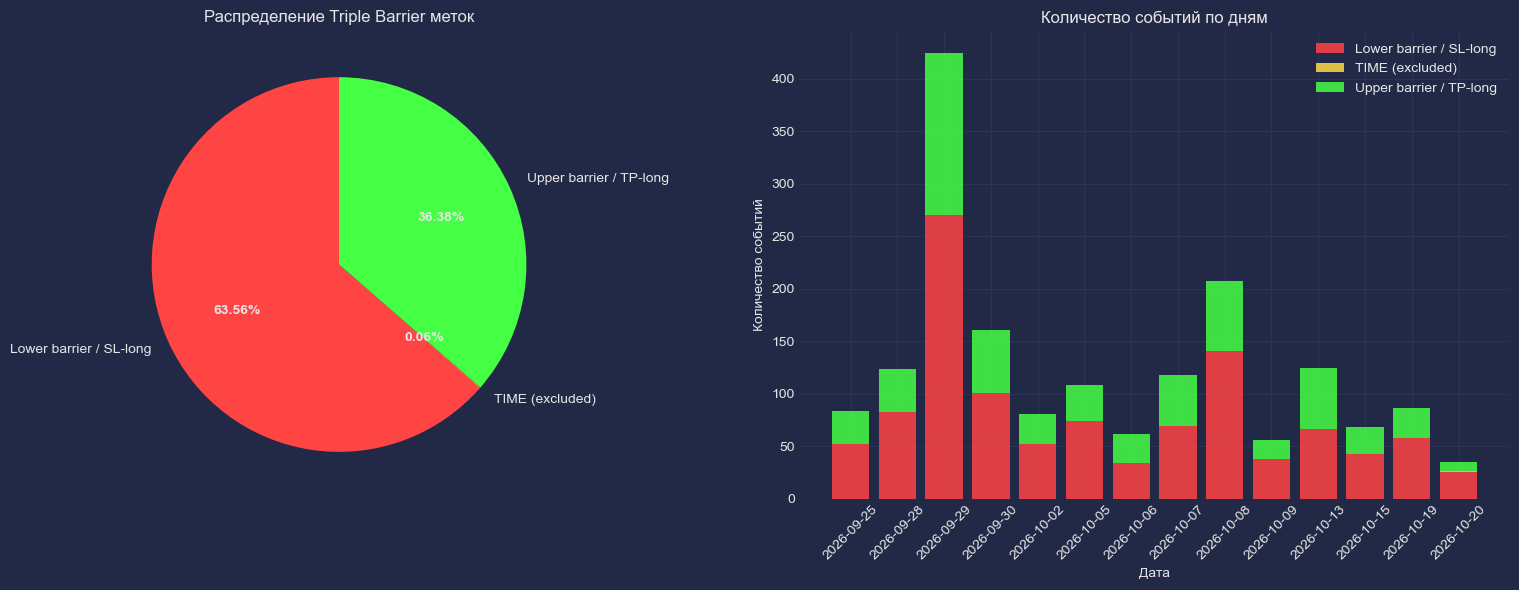


Aligned events before excluding TIME: 1,740
label
-1    1106
 0       1
 1     633
Name: count, dtype: int64


In [12]:
# =============================================================================
# LABELS: CUSUM → TRIPLE BARRIER → EVENT-ALIGNED X/y → BINARY TARGET
# =============================================================================
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

# Use exactly the Dollar Bars that produced FINAL_DATASET.
bars_for_labeling = bars.copy()
if "bar_ts" not in bars_for_labeling.columns:
    raise RuntimeError(f"В bars отсутствует bar_ts. Колонки: {list(bars_for_labeling.columns)}")

rename_map = {
    "open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE",
    "OPEN": "OPEN", "HIGH": "HIGH", "LOW": "LOW", "CLOSE": "CLOSE",
}
bars_for_labeling = bars_for_labeling.rename(columns=rename_map)
required_ohlc = ["HIGH", "LOW", "CLOSE"]
missing_ohlc = [c for c in required_ohlc if c not in bars_for_labeling.columns]
if missing_ohlc:
    raise RuntimeError(f"Для Triple Barrier не хватает OHLC-колонок: {missing_ohlc}")

bars_for_labeling["bar_ts"] = pd.to_datetime(
    bars_for_labeling["bar_ts"], errors="coerce", utc=True
)
bars_for_labeling = (
    bars_for_labeling.dropna(subset=["bar_ts"] + required_ohlc)
    .sort_values("bar_ts")
    .drop_duplicates("bar_ts", keep="last")
    .set_index("bar_ts")
)
bars_for_labeling.index.name = "bar_ts"

events_idx = cusum_filter(
    bars_for_labeling["CLOSE"].astype(float),
    threshold=CUSUM_THRESHOLD,
)
events_idx = pd.DatetimeIndex(events_idx)
events_idx = events_idx[events_idx.isin(bars_for_labeling.index)]
events_idx = events_idx.drop_duplicates().sort_values()

print("=" * 80)
print("CUSUM + TRIPLE BARRIER")
print("=" * 80)
print(f"CUSUM threshold : {CUSUM_THRESHOLD}")
print(f"PT_SL           : {PT_SL} (TP multiplier, SL multiplier)")
print(f"Vertical horizon: {VERTICAL_HORIZON} Dollar Bars")
print(f"Target window   : {TARGET_WINDOW}")
print(f"CUSUM events    : {len(events_idx):,}")
if len(events_idx) == 0:
    raise RuntimeError("CUSUM не нашёл событий. Проверь CUSUM_THRESHOLD и входные бары.")

labeled_all = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_HORIZON,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
if labeled_all is None or labeled_all.empty:
    raise RuntimeError("Triple Barrier вернул пустую таблицу меток.")
if not {"label", "t1"}.issubset(labeled_all.columns):
    raise RuntimeError(
        "Ожидались колонки label и t1; получены: "
        f"{list(labeled_all.columns)}"
    )

labeled_all.index = pd.to_datetime(labeled_all.index, errors="coerce", utc=True)
labeled_all = labeled_all[~labeled_all.index.isna()].sort_index()
labeled_all = labeled_all[labeled_all["label"].isin([-1, 0, 1])].copy()
labeled_all["label"] = labeled_all["label"].astype(int)
labeled_all["t1"] = pd.to_datetime(labeled_all["t1"], errors="coerce", utc=True)

print(f"Triple Barrier events: {len(labeled_all):,}")
print("Raw labels: -1=lower barrier first (SL for LONG), 0=TIME (excluded), +1=upper barrier first (TP for LONG)")
label_counts = labeled_all["label"].value_counts().reindex([-1, 0, 1], fill_value=0)
for value, name in [(-1, "DOWN"), (0, "TIME"), (1, "UP")]:
    count = int(label_counts.loc[value])
    pct = 100 * count / len(labeled_all) if len(labeled_all) else 0
    print(f"  {name:5s}: {count:7,d} ({pct:6.2f}%)")

# Visual diagnostics include TIME so we can see how often the vertical barrier wins.
label_names = {-1: "Lower barrier / SL-long", 0: "TIME (excluded)", 1: "Upper barrier / TP-long"}
label_colors = {-1: "#ff4444", 0: "#ffdd44", 1: "#44ff44"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_counts = [int(label_counts.loc[v]) for v in (-1, 0, 1)]
if sum(plot_counts):
    _, _, autotexts = axes[0].pie(
        plot_counts,
        labels=[label_names[v] for v in (-1, 0, 1)],
        colors=[label_colors[v] for v in (-1, 0, 1)],
        autopct="%1.2f%%",
        startangle=90,
    )
    for t in autotexts:
        t.set_fontsize(10)
        t.set_fontweight("bold")
axes[0].set_title("Распределение Triple Barrier меток")

plot_labels = pd.DataFrame({
    "day": pd.DatetimeIndex(labeled_all.index).date,
    "label": labeled_all["label"].to_numpy(),
})
daily_counts = (
    plot_labels.groupby(["day", "label"]).size()
    .unstack(fill_value=0)
    .reindex(columns=[-1, 0, 1], fill_value=0)
    .sort_index()
)
bottom = np.zeros(len(daily_counts), dtype=float)
for cls in (-1, 0, 1):
    vals = daily_counts[cls].to_numpy()
    axes[1].bar(
        daily_counts.index.astype(str), vals, bottom=bottom,
        label=label_names[cls], color=label_colors[cls], alpha=0.85,
    )
    bottom += vals
axes[1].set_title("Количество событий по дням")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество событий")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

# Event-aligned X/y. One concat avoids pandas' highly-fragmented DataFrame warning.
if len(FINAL_DATASET) != len(X_model):
    raise RuntimeError(
        f"FINAL_DATASET и X_model имеют разную длину: {len(FINAL_DATASET)} vs {len(X_model)}"
    )
model_feature_cols = list(X_model.columns)
feature_table = pd.concat(
    [FINAL_DATASET[["bar_ts"]].reset_index(drop=True),
     X_model.reset_index(drop=True)],
    axis=1,
)
feature_table["bar_ts"] = pd.to_datetime(feature_table["bar_ts"], errors="coerce", utc=True)
feature_table = feature_table.dropna(subset=["bar_ts"]).set_index("bar_ts").sort_index()

X_all_raw = feature_table.reindex(labeled_all.index)[model_feature_cols].copy()
y_all_raw = labeled_all["label"].reindex(X_all_raw.index)
aligned = y_all_raw.notna() & X_all_raw.index.notna()
X_all_raw = X_all_raw.loc[aligned].copy()
y_all_raw = y_all_raw.loc[aligned].astype(int)
labeled_all = labeled_all.reindex(X_all_raw.index)

if not X_all_raw.index.equals(y_all_raw.index):
    raise RuntimeError("X/y event indices are not aligned.")
if X_all_raw.index.has_duplicates:
    raise RuntimeError("Duplicate event timestamps after feature/label alignment.")

print(f"\nAligned events before excluding TIME: {len(X_all_raw):,}")
print(y_all_raw.value_counts().reindex([-1, 0, 1], fill_value=0))

# TIME is not a prediction target. Keep only events where TP or SL won.
directional_mask = y_all_raw.isin([-1, 1])
X_all = X_all_raw.loc[directional_mask].copy()
y_all = y_all_raw.loc[directional_mask].copy()
labeled = labeled_all.reindex(X_all.index).copy()

if set(y_all.unique()) != {-1, 1}:
    raise RuntimeError(f"Ожидались оба directional класса -1/+1; получены {sorted(y_all.unique())}")

# Binary target: lower barrier first=0, upper barrier first=1. TIME is excluded.
label_map = {-1: 0, 1: 1}
y_binary = y_all.map(label_map).astype(int)

# Chronological 75/25 holdout split. Purge training outcomes reaching holdout start.
if len(X_all) < 100:
    raise RuntimeError(f"Слишком мало directional событий: {len(X_all)}")
split_idx = int(len(X_all) * 0.75)
if split_idx <= 0 or split_idx >= len(X_all):
    raise RuntimeError("Невозможно построить chronological split.")

HOLDOUT_START = X_all.index[split_idx]
train_candidate_index = X_all.index[:split_idx]
test_index = X_all.index[split_idx:]
train_end_times = labeled.reindex(train_candidate_index)["t1"]
train_keep = train_end_times.notna() & (train_end_times < HOLDOUT_START)
train_index = train_candidate_index[train_keep.to_numpy()]


## 8. Конфигурация и purged walk-forward folds

Все параметры стратегии фиксируются до сравнения. Сетка порогов — 0.50, 0.55, 0.60, 0.65. Для `threshold > 0.5` открываем сделку только если модель достаточно уверена в одной из сторон; иначе пропускаем событие. `0.50` — контроль без зоны отказа.

In [13]:

SEED = 63
INITIAL_CAPITAL = 100_000.0
COMMISSION = 0.0006      # за каждую сторону сделки
SLIPPAGE = 0.0001        # adverse execution на каждой стороне
CONFIDENCE_THRESHOLDS = (0.50, 0.55, 0.60, 0.65)
FOLD_SPECS = [("WF1", 0.50, 0.65), ("WF2", 0.65, 0.80), ("WF3", 0.80, 1.00)]
MODEL_NAMES = ["RandomForest", "LightGBM", "XGBoost", "CatBoost"]
FEATURE_VARIANTS = ["base474", "ffd_augmented"]

required_objects = ["bars", "X_all", "y_binary", "labeled", "FINAL_DATASET"]
missing_objects = [x for x in required_objects if x not in globals()]
if missing_objects:
    raise RuntimeError(f"Не хватает объектов подготовки: {missing_objects}")

bars = bars.copy()
bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)
bars = bars.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)
if "open" not in bars:
    if "OPEN" in bars: bars["open"] = bars["OPEN"]
    elif "close" in bars: bars["open"] = bars["close"]
    elif "CLOSE" in bars: bars["open"] = bars["CLOSE"]
    else: raise RuntimeError("В bars нет open/OPEN или close/CLOSE.")
bars["open"] = pd.to_numeric(bars["open"], errors="coerce")
for lower, upper in [("high","HIGH"),("low","LOW"),("close","CLOSE")]:
    if lower not in bars and upper in bars: bars[lower] = bars[upper]
    bars[lower] = pd.to_numeric(bars[lower], errors="coerce")
if "close" not in bars or "high" not in bars or "low" not in bars:
    raise RuntimeError(f"Для OHLC backtest нужны open/high/low/close. Есть: {list(bars.columns)}")
bars = bars.dropna(subset=["high","low","close"]).reset_index(drop=True)
bars_by_ts = bars.set_index("bar_ts", drop=False)

X_all = X_all.copy()
X_all.index = pd.to_datetime(X_all.index, utc=True, errors="coerce")
y_binary = y_binary.copy()
y_binary.index = pd.to_datetime(y_binary.index, utc=True, errors="coerce")
labeled = labeled.copy()
labeled.index = pd.to_datetime(labeled.index, utc=True, errors="coerce")
labeled["t1"] = pd.to_datetime(labeled["t1"], utc=True, errors="coerce")
common = X_all.index.intersection(y_binary.index).intersection(labeled.index)
X_all, y_binary, labeled = X_all.loc[common].sort_index(), y_binary.loc[common].sort_index(), labeled.loc[common].sort_index()
if X_all.index.has_duplicates or not X_all.index.equals(y_binary.index) or not X_all.index.equals(labeled.index):
    raise RuntimeError("X/y/labels имеют дубли или несовпадающие event timestamps.")
if set(y_binary.unique()) != {0, 1}:
    raise RuntimeError(f"Ожидались только бинарные классы 0/1, получены {sorted(y_binary.unique())}")
if (labeled["label"].eq(0)).any():
    raise RuntimeError("TIME events попали в labeled после фильтрации — остановка, чтобы не обучать третий класс.")
if not {"upper", "lower", "t1"}.issubset(labeled.columns):
    raise RuntimeError("В labeled отсутствуют upper/lower/t1. Проверь контракт triple_barrier_labeling().")

# Barrier levels must be actual price levels around the event close; otherwise PnL is not trustworthy.
close_at_event = bars.set_index("bar_ts")["close"].reindex(labeled.index)
upper_num = pd.to_numeric(labeled["upper"], errors="coerce")
lower_num = pd.to_numeric(labeled["lower"], errors="coerce")
barrier_valid = (upper_num > close_at_event) & (lower_num < close_at_event) & upper_num.notna() & lower_num.notna()
barrier_valid_share = float(barrier_valid.mean()) if len(barrier_valid) else 0.0
print(f"Barrier-price contract: valid={barrier_valid_share:.2%} ({int(barrier_valid.sum())}/{len(barrier_valid)})")
if barrier_valid_share < 0.90:
    raise RuntimeError(
        "upper/lower выглядят не как ценовые уровни относительно close события. "
        "Не запускаю PnL с неверной интерпретацией барьеров. "
        f"Примеры upper/lower/close: {pd.DataFrame({'upper':upper_num,'lower':lower_num,'close':close_at_event}).head(8).to_dict('records')}"
    )

n = len(X_all)
folds = []
for name, train_frac, val_end_frac in FOLD_SPECS:
    train_end = int(n * train_frac)
    val_end_pos = min(n, int(n * val_end_frac))
    train_candidates = X_all.index[:train_end]
    val_all = X_all.index[train_end:val_end_pos]
    if len(val_all) == 0: continue
    val_start = val_all[0]
    val_end = X_all.index[val_end_pos] if val_end_pos < n else None
    train_t1 = labeled.loc[train_candidates, "t1"]
    train_idx = train_candidates[(train_t1.notna() & (train_t1 < val_start)).to_numpy()]
    val_t1 = labeled.loc[val_all, "t1"]
    val_mask = val_t1.notna()
    if val_end is not None: val_mask &= val_t1 < val_end
    val_idx = val_all[val_mask.to_numpy()]
    if len(train_idx) < 50 or len(val_idx) < 20 or y_binary.loc[train_idx].nunique() != 2:
        warnings.warn(f"{name} пропущен: train={len(train_idx)}, validation={len(val_idx)}")
        continue
    folds.append(dict(name=name, train_idx=train_idx, val_idx=val_idx, val_start=val_start, val_end=val_end))
if len(folds) < 2: raise RuntimeError(f"Пригодных WF folds всего {len(folds)}; нужно минимум 2.")
print("Binary events only:", len(X_all))
print("Binary classes (0=lower barrier first; 1=upper barrier first):", y_binary.value_counts().to_dict())
print("Folds:", [(f["name"], len(f["train_idx"]), len(f["val_idx"])) for f in folds])


Barrier-price contract: valid=100.00% (1739/1739)
Binary events only: 1739
Binary classes (0=lower barrier first; 1=upper barrier first): {0: 1106, 1: 633}
Folds: [('WF1', 842, 232), ('WF2', 1101, 233), ('WF3', 1363, 348)]


## 9. AFML: uniqueness weights и дробное дифференцирование

Uniqueness учитывает перекрытие интервалов `[event_ts, t1]`. Fractional differentiation (FFD) тестируется как **добавка** к базовым признакам, а не замена всех 474 признаков: выбираются только числовые кандидаты, похожие на уровни цены/накопительные величины. Преобразование использует только прошлые значения, без центрирования и без доступа к будущему.

In [14]:

def uniqueness_weights(train_index, event_labels, all_bar_times):
    train_index = pd.DatetimeIndex(train_index)
    t1 = pd.to_datetime(event_labels.reindex(train_index)["t1"], errors="coerce", utc=True)
    ok = t1.notna()
    starts_idx, ends_idx = train_index[ok.to_numpy()], t1.loc[train_index[ok.to_numpy()]]
    if len(starts_idx) == 0: raise ValueError("Нет train events с t1.")
    bar_ns = pd.DatetimeIndex(all_bar_times).asi8
    s = np.clip(np.searchsorted(bar_ns, starts_idx.asi8, side="left"), 0, len(bar_ns)-1)
    e = np.clip(np.searchsorted(bar_ns, pd.DatetimeIndex(ends_idx).asi8, side="left"), 0, len(bar_ns)-1)
    e = np.maximum(e, s)
    diff = np.zeros(len(bar_ns)+1, dtype=np.int64)
    np.add.at(diff, s, 1); np.add.at(diff, e+1, -1)
    conc = np.cumsum(diff[:-1])
    inv = np.zeros(len(bar_ns), dtype=float); inv[conc > 0] = 1.0 / conc[conc > 0]
    prefix = np.r_[0.0, np.cumsum(inv)]
    w = (prefix[e+1] - prefix[s]) / (e-s+1)
    out = pd.Series(w, index=starts_idx, name="uniqueness_weight")
    out = out.replace([np.inf,-np.inf],np.nan).dropna()
    if out.empty or (out <= 0).any(): raise RuntimeError("Некорректные uniqueness weights.")
    return out / out.mean()

def prepare_matrices(Xtr_raw, Xva_raw):
    a = Xtr_raw.apply(pd.to_numeric, errors="coerce").replace([np.inf,-np.inf],np.nan)
    b = Xva_raw.reindex(columns=a.columns).apply(pd.to_numeric, errors="coerce").replace([np.inf,-np.inf],np.nan)
    keep = a.columns[~a.isna().all()].tolist()
    a, b = a[keep], b[keep]
    imp = SimpleImputer(strategy="median")
    A = pd.DataFrame(imp.fit_transform(a), index=a.index, columns=keep)
    B = pd.DataFrame(imp.transform(b), index=b.index, columns=keep)
    return A, B, imp

def fracdiff_weights(d, threshold=1e-4, max_size=1000):
    w = [1.0]
    for k in range(1, max_size):
        w.append(-w[-1] * (d-k+1) / k)
        if abs(w[-1]) < threshold: break
    return np.asarray(w[::-1], dtype=float)

def fracdiff_series(series, d, threshold=1e-4):
    x = pd.to_numeric(series, errors="coerce").astype(float)
    w = fracdiff_weights(d, threshold=threshold)
    out = pd.Series(np.nan, index=x.index, dtype=float)
    arr = x.to_numpy()
    for i in range(len(w)-1, len(arr)):
        window = arr[i-len(w)+1:i+1]
        if np.isfinite(window).all():
            out.iloc[i] = float(np.dot(w, window))
    return out

# Choose a small, explicit subset; do not mass-transform all features.
candidate_cols = [c for c in X_all.columns if re.search(r"(close|price|vwap|cum|level|ema|sma)", str(c), re.I)]
candidate_cols = candidate_cols[:8]
print("FFD candidates:", candidate_cols)
ffd_parts = []
for col in candidate_cols:
    for d in (0.3, 0.5, 0.7):
        ffd_parts.append(fracdiff_series(X_all[col], d).rename(f"FFD_d{d}_{col}"))
X_ffd_all = pd.concat([X_all, *ffd_parts], axis=1) if ffd_parts else X_all.copy()

# Causal entropy features from historical bar returns (rolling windows use current/past only).
bar_close = bars.set_index("bar_ts")["close"].astype(float).sort_index()
bar_ret = np.log(bar_close).diff()
def rolling_sign_entropy(x, window=50):
    signs = np.sign(x)
    p = signs.rolling(window, min_periods=window).apply(
        lambda a: np.mean(a > 0), raw=True
    ).clip(1e-6, 1-1e-6)
    # Binary entropy of positive vs non-positive returns, in bits.
    return -(p*np.log2(p) + (1-p)*np.log2(1-p))
entropy_bar = pd.DataFrame(index=bar_close.index)
entropy_bar["entropy_sign_50"] = rolling_sign_entropy(bar_ret, 50)
entropy_bar["entropy_absret_50"] = bar_ret.abs().rolling(50, min_periods=50).std()
entropy_bar["trend_return_50"] = bar_ret.rolling(50, min_periods=50).sum()
entropy_events = entropy_bar.reindex(X_all.index, method="ffill")
X_entropy_all = pd.concat([X_all, entropy_events.add_prefix("ENTROPY_")], axis=1)

print("Feature matrices:", {"base474": X_all.shape, "ffd_augmented": X_ffd_all.shape,
                             "entropy_augmented": X_entropy_all.shape})


FFD candidates: ['base__base__close', 'base__base__close_lag_1', 'base__base__close_lag_2', 'base__base__close_lag_3', 'base__base__close_roll_mean_5', 'base__base__close_roll_std_5', 'base__base__close_roll_min_5', 'base__base__close_roll_max_5']
Feature matrices: {'base474': (1739, 474), 'ffd_augmented': (1739, 498), 'entropy_augmented': (1739, 477)}


## 10. Модельный zoo: Random Forest, LightGBM, XGBoost, CatBoost

Каждая доступная модель обучается на одинаковых временных folds. Для каждого семейства сравниваем обычное обучение и обучение с uniqueness weights. Если пакет отсутствует в окружении, он не маскируется: записывается явный статус `SKIPPED_DEPENDENCY`. Модельная метрика — OOS, без подбора гиперпараметров по validation.

In [15]:

def make_model(name):
    if name == "RandomForest":
        return RandomForestClassifier(
            n_estimators=500, max_depth=8, min_samples_leaf=8,
            max_features="sqrt", class_weight=None, random_state=SEED, n_jobs=-1
        )
    if name == "LightGBM":
        if LGBMClassifier is None: return None
        return LGBMClassifier(
            n_estimators=400, learning_rate=0.03, num_leaves=15,
            max_depth=-1, min_child_samples=20, subsample=0.85,
            colsample_bytree=0.85, reg_lambda=5.0, verbosity=-1,
            random_state=SEED, n_jobs=-1
        )
    if name == "XGBoost":
        if XGBClassifier is None: return None
        return XGBClassifier(
            n_estimators=400, max_depth=4, learning_rate=0.03,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=5.0,
            objective="binary:logistic", eval_metric="logloss",
            random_state=SEED, n_jobs=-1
        )
    if name == "CatBoost":
        if CatBoostClassifier is None: return None
        return CatBoostClassifier(
            iterations=500, depth=6, learning_rate=0.04, loss_function="Logloss",
            l2_leaf_reg=5.0, random_seed=SEED, verbose=False,
            allow_writing_files=False, thread_count=-1
        )
    raise KeyError(name)

def fit_model(name, Xtr, ytr, weights=None):
    model = make_model(name)
    if model is None: return None
    fit_kwargs = {}
    if weights is not None: fit_kwargs["sample_weight"] = weights.reindex(Xtr.index).to_numpy(float)
    model.fit(Xtr, ytr, **fit_kwargs)
    return model

def calc_metrics(y_true, p1):
    yt = np.asarray(y_true, dtype=int); p1 = np.clip(np.asarray(p1, float), 1e-6, 1-1e-6)
    pred = (p1 >= 0.5).astype(int)
    return {
        "n": len(yt), "accuracy": accuracy_score(yt,pred),
        "balanced_accuracy": balanced_accuracy_score(yt,pred),
        "macro_f1": f1_score(yt,pred,average="macro",zero_division=0),
        "precision_up": precision_score(yt,pred,zero_division=0),
        "recall_up": recall_score(yt,pred,zero_division=0),
        "mcc": matthews_corrcoef(yt,pred),
        "roc_auc": roc_auc_score(yt,p1) if len(np.unique(yt)) == 2 else np.nan,
        "log_loss": log_loss(yt,np.c_[1-p1,p1],labels=[0,1]),
        "brier": brier_score_loss(yt,p1),
        "pred_up_share": float((pred==1).mean()), "actual_up_share": float((yt==1).mean())
    }

model_metrics_rows, prediction_store, model_status_rows, weight_rows = [], {}, [], []
for fold in folds:
    name, tr_idx, va_idx = fold["name"], fold["train_idx"], fold["val_idx"]
    weights = uniqueness_weights(tr_idx, labeled, bars["bar_ts"])
    weight_rows.append({
        "fold": name, "train_events": len(weights), "weight_min": weights.min(),
        "weight_median": weights.median(), "weight_max": weights.max(), "weight_mean": weights.mean(),
        "weight_std": weights.std(ddof=0), "effective_sample_size": weights.sum()**2/(weights.pow(2).sum()),
        "train_class_0": int((y_binary.loc[weights.index]==0).sum()),
        "train_class_1": int((y_binary.loc[weights.index]==1).sum()), "validation_events": len(va_idx)
    })
    for feature_variant, feature_matrix in [("base474", X_all), ("ffd_augmented", X_ffd_all), ("entropy_augmented", X_entropy_all)]:
        # Run all four model families on both feature variants.
        for model_name in MODEL_NAMES:
            for weight_mode in ("unweighted", "uniqueness_weighted"):
                key = (name, feature_variant, model_name, weight_mode)
                if make_model(model_name) is None:
                    model_status_rows.append({"fold":name,"feature_variant":feature_variant,"model":model_name,
                                              "weight_mode":weight_mode,"status":"SKIPPED_DEPENDENCY"})
                    continue
                Xtr, Xva, _ = prepare_matrices(feature_matrix.loc[tr_idx], feature_matrix.loc[va_idx])
                ytr, yva = y_binary.loc[Xtr.index], y_binary.loc[Xva.index]
                w = weights.reindex(Xtr.index).dropna()
                common_idx = Xtr.index.intersection(w.index)
                Xtr, ytr, w = Xtr.loc[common_idx], ytr.loc[common_idx], w.loc[common_idx]
                sw = None if weight_mode == "unweighted" else w
                model = fit_model(model_name, Xtr, ytr, sw)
                p1 = model.predict_proba(Xva)[:,1]
                model_metrics_rows.append({"fold":name,"feature_variant":feature_variant,"model":model_name,
                                           "weight_mode":weight_mode,"train_n":len(Xtr),"validation_n":len(Xva),
                                           **calc_metrics(yva,p1)})
                prediction_store[key] = {"model":model,"p_up":pd.Series(p1,index=Xva.index),
                                         "y":yva.copy(),"X_validation":Xva.copy(),"feature_variant":feature_variant}
                model_status_rows.append({"fold":name,"feature_variant":feature_variant,"model":model_name,
                                          "weight_mode":weight_mode,"status":"OK"})
metrics_df = pd.DataFrame(model_metrics_rows)
weight_diagnostics_df = pd.DataFrame(weight_rows)
model_status_df = pd.DataFrame(model_status_rows)
display(weight_diagnostics_df)
display(metrics_df.sort_values(["feature_variant","model","weight_mode","fold"]))
display(model_status_df[model_status_df.status != "OK"])


,fold,train_events,weight_min,weight_median,weight_max,weight_mean,weight_std,effective_sample_size,train_class_0,train_class_1,validation_events
0,WF1,842,0.783849,0.967099,3.438504,1.0,0.222265,802.361825,537,305,232
1,WF2,1101,0.783236,0.974911,3.561697,1.0,0.199902,1058.693714,697,404,233
2,WF3,1363,0.786055,0.979440,4.472336,1.0,0.193733,1313.693929,872,491,348


,fold,feature_variant,model,weight_mode,train_n,validation_n,n,accuracy,balanced_accuracy,macro_f1,precision_up,recall_up,mcc,roc_auc,log_loss,brier,pred_up_share,actual_up_share
7,WF1,base474,CatBoost,uniqueness_weighted,842,232,232,0.560345,0.544410,0.543941,0.447917,0.467391,0.088219,0.533929,0.849316,0.295514,0.413793,0.396552
31,WF2,base474,CatBoost,uniqueness_weighted,1101,233,233,0.639485,0.553197,0.551923,0.433962,0.298701,0.119385,0.553863,0.675206,0.235172,0.227468,0.330472
55,WF3,base474,CatBoost,uniqueness_weighted,1363,348,348,0.577586,0.487236,0.420939,0.322581,0.073529,-0.043725,0.525666,0.746768,0.264760,0.089080,0.390805
6,WF1,base474,CatBoost,unweighted,842,232,232,0.517241,0.499379,0.499229,0.395833,0.413043,-0.001234,0.506444,0.897127,0.314828,0.413793,0.396552
30,WF2,base474,CatBoost,unweighted,1101,233,233,0.635193,0.546703,0.544430,0.423077,0.285714,0.105522,0.544289,0.689513,0.240140,0.223176,0.330472
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37,WF2,ffd_augmented,XGBoost,uniqueness_weighted,1101,233,233,0.690987,0.588370,0.586798,0.564103,0.285714,0.222694,0.555528,0.658537,0.227749,0.167382,0.330472
61,WF3,ffd_augmented,XGBoost,uniqueness_weighted,1363,348,348,0.586207,0.495630,0.430416,0.366667,0.080882,-0.015195,0.543320,0.751522,0.265575,0.086207,0.390805
12,WF1,ffd_augmented,XGBoost,unweighted,842,232,232,0.568966,0.532919,0.531010,0.445946,0.358696,0.069102,0.521817,0.835375,0.295054,0.318966,0.396552
36,WF2,ffd_augmented,XGBoost,unweighted,1101,233,233,0.699571,0.601357,0.602815,0.585366,0.311688,0.250408,0.544206,0.672801,0.232937,0.175966,0.330472


,fold,feature_variant,model,weight_mode,status


## 11. Диагностика feature importance без массового отбора

Сохраняем importance только как диагностику: это не автоматический отбор признаков и не основание удалять признаки по одному удачному fold. В каждом WF-fold дерево обучается на train, а важности сохраняются отдельно, чтобы проверить устойчивость между временными отрезками.

In [18]:

importance_rows = []
for fold in folds:
    tr, va = fold["train_idx"], fold["val_idx"]
    Xtr, _, _ = prepare_matrices(X_all.loc[tr], X_all.loc[va])
    ytr = y_binary.loc[Xtr.index]
    model = make_model("CatBoost")
    if model is None: model = make_model("RandomForest")
    model.fit(Xtr,ytr)
    values = getattr(model,"feature_importances_",None)
    if values is None: continue
    for feature, value in zip(Xtr.columns,values):
        importance_rows.append({"fold":fold["name"],"model":type(model).__name__,
                                "feature":feature,"importance":float(value)})
feature_importance_df = pd.DataFrame(importance_rows)
if not feature_importance_df.empty:
    display(feature_importance_df.groupby("feature",as_index=False).agg(
        mean_importance=("importance","mean"),std_importance=("importance","std"),
        folds=("fold","nunique")
    ).sort_values("mean_importance",ascending=False).head(40))
else:
    print("Feature importance skipped: no supported tree model exposed feature_importances_.")


,feature,mean_importance,std_importance,folds
25,base__base__close_roll_skew_5,4.100996,0.688443,3
31,base__base__count,2.823261,0.810424,3
28,base__base__close_roll_std_5,2.599650,0.903947,3
42,base__base__macd_signal,2.313364,0.286925,3
2,base__base__bb_position,2.093311,0.425433,3
50,base__base__value,2.079217,0.137369,3
11,base__base__close_roll_kurt_10,1.814408,0.446074,3
55,base__base__volume_roll_kurt_10,1.779409,0.473718,3
30,base__base__close_x_volume,1.732949,0.260039,3
12,base__base__close_roll_kurt_20,1.646289,0.566636,3


## 12. Sequential Bootstrap (AFML) для Random Forest

Это отдельный контроль для ансамбля: вместо обычного обучения с повторным использованием каждой строки строится bootstrap-последовательность, где вероятность следующего события зависит от средней уникальности относительно уже выбранных событий. Результат сравнивается с обычным RF на тех же folds. Это дополнительный эксперимент, не замена базовой модели.

In [19]:

def sequential_bootstrap_indices(event_index, event_labels, bar_times, n_draws=None, seed=SEED):
    rng = np.random.default_rng(seed)
    event_index = pd.DatetimeIndex(event_index)
    ends = pd.to_datetime(event_labels.reindex(event_index)["t1"], errors="coerce", utc=True)
    ok = ends.notna()
    event_index, ends = event_index[ok.to_numpy()], ends.loc[event_index[ok.to_numpy()]]
    bar_ns = pd.DatetimeIndex(bar_times).asi8
    starts = np.clip(np.searchsorted(bar_ns, event_index.asi8, side="left"), 0, len(bar_ns)-1)
    stops = np.clip(np.searchsorted(bar_ns, pd.DatetimeIndex(ends).asi8, side="left"), 0, len(bar_ns)-1)
    stops = np.maximum(stops, starts)
    n = len(event_index); draws = int(n_draws or n)
    if n == 0: return pd.DatetimeIndex([])
    concurrency = np.zeros(len(bar_ns), dtype=np.int32)
    selected = []
    for _ in range(draws):
        avg_u = np.empty(n, dtype=float)
        for j, (a,b) in enumerate(zip(starts, stops)):
            # Marginal uniqueness if candidate j were added to current bootstrap.
            avg_u[j] = np.mean(1.0 / (concurrency[a:b+1] + 1.0))
        probs = avg_u / avg_u.sum()
        j = int(rng.choice(n, p=probs))
        selected.append(event_index[j])
        concurrency[starts[j]:stops[j]+1] += 1
    return pd.DatetimeIndex(selected)

seqboot_rows = []
for fold in folds:
    tr, va = fold["train_idx"], fold["val_idx"]
    Xtr, Xva, _ = prepare_matrices(X_all.loc[tr], X_all.loc[va])
    ytr, yva = y_binary.loc[Xtr.index], y_binary.loc[Xva.index]
    boot_idx = sequential_bootstrap_indices(Xtr.index, labeled, bars["bar_ts"], seed=SEED)
    # Repeated timestamps intentionally represent bootstrap multiplicity.
    Xboot = Xtr.reindex(boot_idx)
    yboot = y_binary.reindex(boot_idx)
    model = make_model("CatBoost")
    model.fit(Xboot, yboot)
    p = model.predict_proba(Xva)[:,1]
    prediction_store[(fold["name"],"base474","CatBoost","sequential_bootstrap")] = {
        "model":model,"p_up":pd.Series(p,index=Xva.index),"y":yva.copy(),"X_validation":Xva.copy(),
        "feature_variant":"base474"
    }
    seqboot_rows.append({"fold":fold["name"],"model":"CatBoost","sampling":"sequential_bootstrap",
                         "train_draws":len(boot_idx),"validation_n":len(Xva),**calc_metrics(yva,p)})
sequential_bootstrap_metrics = pd.DataFrame(seqboot_rows)
display(sequential_bootstrap_metrics)


,fold,model,sampling,train_draws,validation_n,n,accuracy,balanced_accuracy,macro_f1,precision_up,recall_up,mcc,roc_auc,log_loss,brier,pred_up_share,actual_up_share
0,WF1,CatBoost,sequential_bootstrap,842,232,232,0.487069,0.438975,0.427208,0.292308,0.206522,-0.132947,0.480047,0.869764,0.309958,0.280172,0.396552
1,WF2,CatBoost,sequential_bootstrap,1101,233,233,0.678112,0.549159,0.525973,0.541667,0.168831,0.152147,0.537213,0.717048,0.238988,0.103004,0.330472
2,WF3,CatBoost,sequential_bootstrap,1363,348,348,0.586207,0.503538,0.456509,0.404762,0.125000,0.010598,0.534684,0.784979,0.275395,0.120690,0.390805


## 13. Causal OHLC backtest — сравнение старой и исправленной логики барьеров

В этой ячейке на **одних и тех же `prediction_store`, `labeled`, барах и folds** рассчитываются два варианта:

- `LEGACY_REANCHORED` — прежняя логика, только для диагностики различий;
- `FIXED_STATIONARY` — исправленная логика, которая должна использоваться дальше.

**Контракт исходных уровней:** `upper` и `lower` — абсолютные цены, построенные разметчиком для сигнального события. Они не переносятся к цене входа на следующем OPEN.

- LONG: `TP = upper`, `SL = lower`.
- SHORT: `TP = lower`, `SL = upper`.
- Сигнал известен после `CLOSE[t]`, вход — на `OPEN[t+1]`.
- Если гэп/проскальзывание уже поставили цену входа за исходный барьер, исправленный вариант пропускает сделку, а не назначает ей новые уровни.
- Если TP и SL затронуты в одной OHLC-свече, применяется консервативное правило `SL first`.

`PT_SL` — множители Triple Barrier, а не проценты напрямую: фактические `upper/lower` зависят также от target/волатильности. Если меняешь `PT_SL`, надо заново построить разметку и обучить модели. Сначала сравниваем механику бэктеста при прежних labels, а асимметричный эксперимент запускаем отдельным полным прогоном.


In [20]:

def _price_level_legacy(value, reference):
    try:
        v = float(value)
        if not np.isfinite(v): return np.nan
        return v
    except Exception: return np.nan

def simulate_fold_backtest_legacy(fold, pred, threshold, model_name, feature_variant, weight_mode, p_good=None, meta_cutoff=None):
    probs = pred["p_up"].dropna().sort_index()
    y_oos = pred["y"].reindex(probs.index)
    # Threshold logic: 0.50 gives binary direction; higher thresholds create a no-trade zone.
    if threshold <= 0.5:
        sig = pd.Series(np.where(probs >= 0.5, 1, -1), index=probs.index)
    else:
        sig = pd.Series(np.where(probs >= threshold, 1,
                         np.where(probs <= 1-threshold, -1, 0)), index=probs.index)
    if p_good is not None and meta_cutoff is not None:
        pg = p_good.reindex(sig.index).fillna(0.0)
        sig.loc[pg < meta_cutoff] = 0
    trade_rows = []
    equity = float(INITIAL_CAPITAL)
    # Mark-to-market equity at each bar while a position is open; used for intratrade drawdown.
    equity_curve_values = [equity]
    last_exit_pos = -1
    ts_to_pos = {ts:i for i,ts in enumerate(bars["bar_ts"])}
    for signal_ts, side in sig.items():
        if side == 0 or signal_ts not in ts_to_pos: continue
        signal_pos = ts_to_pos[signal_ts]
        entry_pos = signal_pos + 1
        if entry_pos >= len(bars) or entry_pos <= last_exit_pos: continue
        label_row = labeled.loc[signal_ts]
        signal_close = float(bars.iloc[signal_pos]["close"])
        upper = _price_level_legacy(label_row.get("upper", np.nan), signal_close)
        lower = _price_level_legacy(label_row.get("lower", np.nan), signal_close)
        # Reject malformed barrier prices; don't silently turn them into a trade.
        if not (np.isfinite(upper) and np.isfinite(lower) and upper > signal_close > lower):
            continue
        # For LONG, upper is TP and lower is SL. For SHORT, lower is TP and upper is SL.
        if side == 1:
            tp_dist, sl_dist = upper-signal_close, signal_close-lower
        else:
            tp_dist, sl_dist = signal_close-lower, upper-signal_close
        entry_bar = bars.iloc[entry_pos]
        raw_entry = float(entry_bar["open"]) if np.isfinite(entry_bar["open"]) else float(entry_bar["close"])
        if side == 1:
            entry_px = raw_entry * (1 + SLIPPAGE)
            tp_px, sl_px = entry_px + tp_dist, entry_px - sl_dist
        else:
            entry_px = raw_entry * (1 - SLIPPAGE)
            tp_px, sl_px = entry_px - tp_dist, entry_px + sl_dist
        max_exit_pos = min(len(bars)-1, entry_pos + int(VERTICAL_HORIZON) - 1)
        # Do not let an OOS trade leak into the next WF fold. Skip boundary trades
        # unless their full predeclared horizon fits inside this validation block.
        fold_end = fold.get("val_end")
        if fold_end is not None and bars.iloc[max_exit_pos]["bar_ts"] >= fold_end:
            continue
        exit_pos, exit_reason, raw_exit = max_exit_pos, "VERTICAL_CLOSE", float(bars.iloc[max_exit_pos]["close"])
        for j in range(entry_pos, max_exit_pos+1):
            hi, lo = float(bars.iloc[j]["high"]), float(bars.iloc[j]["low"])
            if side == 1:
                hit_sl, hit_tp = lo <= sl_px, hi >= tp_px
            else:
                hit_sl, hit_tp = hi >= sl_px, lo <= tp_px
            # Conservative ambiguity policy: if both touched inside one OHLC bar, SL wins.
            if hit_sl:
                exit_pos, exit_reason, raw_exit = j, "SL", sl_px
                break
            if hit_tp:
                exit_pos, exit_reason, raw_exit = j, "TP", tp_px
                break
        if side == 1: exit_px = raw_exit * (1 - SLIPPAGE)
        else: exit_px = raw_exit * (1 + SLIPPAGE)
        qty = equity / entry_px if entry_px > 0 else 0.0
        gross_pnl = qty * (exit_px-entry_px) * side
        fees = COMMISSION * (abs(qty*entry_px) + abs(qty*exit_px))
        net_pnl = gross_pnl - fees
        start_equity = equity
        # Track close-to-close unrealized equity during the trade, including entry costs and
        # hypothetical liquidation slippage/commission. On the exit bar use the actual exit fill.
        entry_fee = COMMISSION * abs(qty * entry_px)
        for mark_pos in range(entry_pos, exit_pos + 1):
            mark_raw = raw_exit if mark_pos == exit_pos else float(bars.iloc[mark_pos]["close"])
            mark_exec = mark_raw * (1 - SLIPPAGE) if side == 1 else mark_raw * (1 + SLIPPAGE)
            mark_gross = qty * (mark_exec - entry_px) * side
            mark_exit_fee = COMMISSION * abs(qty * mark_exec)
            equity_curve_values.append(start_equity + mark_gross - entry_fee - mark_exit_fee)
        equity += net_pnl
        # Replace final mark with realized equity after the actual close.
        equity_curve_values[-1] = equity
        trade_ret = net_pnl / start_equity if start_equity else np.nan
        trade_rows.append({
            "fold":fold["name"],"model":model_name,"feature_variant":feature_variant,"weight_mode":weight_mode,
            "threshold":threshold,"meta_cutoff":meta_cutoff,"signal_ts":signal_ts,"entry_ts":bars.iloc[entry_pos]["bar_ts"],
            "exit_ts":bars.iloc[exit_pos]["bar_ts"],"side":"LONG" if side==1 else "SHORT",
            "p_up":float(probs.loc[signal_ts]),"label_outcome":int(y_oos.loc[signal_ts]) if pd.notna(y_oos.loc[signal_ts]) else np.nan,
            "entry_price":entry_px,"exit_price":exit_px,"exit_reason":exit_reason,"quantity":qty,
            "gross_pnl":gross_pnl,"fees":fees,"net_pnl":net_pnl,"trade_return":trade_ret,
            "equity_before":start_equity,"equity_after":equity,"holding_bars":exit_pos-entry_pos+1
        })
        last_exit_pos = exit_pos
    trades = pd.DataFrame(trade_rows)
    if trades.empty:
        return {"fold":fold["name"],"model":model_name,"feature_variant":feature_variant,
                "weight_mode":weight_mode,"threshold":threshold,"meta_cutoff":meta_cutoff,"signals":int((sig!=0).sum()),
                "trades":0,"equity_final":INITIAL_CAPITAL,"total_return":0.0,
                "max_drawdown":0.0,"win_rate":np.nan,"profit_factor":np.nan,
                "avg_trade_return":np.nan,"expectancy":np.nan,"sharpe_trade":np.nan,
                "backtest_status":"NO_TRADES"}, trades
    eq = pd.Series(equity_curve_values, dtype=float)
    dd = eq / eq.cummax() - 1.0
    wins = trades.loc[trades.net_pnl>0,"net_pnl"].sum()
    losses = -trades.loc[trades.net_pnl<0,"net_pnl"].sum()
    rets = trades["trade_return"].replace([np.inf,-np.inf],np.nan).dropna()
    return {
        "fold":fold["name"],"model":model_name,"feature_variant":feature_variant,"weight_mode":weight_mode,
        "threshold":threshold,"meta_cutoff":meta_cutoff,"signals":int((sig!=0).sum()),"trades":len(trades),
        "equity_final":float(trades["equity_after"].iloc[-1]),
        "total_return":float(trades["equity_after"].iloc[-1]/INITIAL_CAPITAL-1),
        "max_drawdown":float(dd.min()),"win_rate":float((trades.net_pnl>0).mean()),
        "backtest_status":"OK","profit_factor":float(wins/losses) if losses>0 else np.inf,
        "avg_trade_return":float(rets.mean()),"expectancy":float(trades["net_pnl"].mean()),
        "sharpe_trade":float(rets.mean()/rets.std(ddof=1)*np.sqrt(len(rets))) if len(rets)>1 and rets.std(ddof=1)>0 else np.nan
    }, trades


# Fixed-barrier engine: original absolute upper/lower prices are not re-anchored.
from src.backtesting.fixed_barrier_backtest import simulate_fold_backtest_fixed_barriers


def simulate_fold_backtest(fold, pred, threshold, model_name, feature_variant,
                           weight_mode, p_good=None, meta_cutoff=None):
    """Production/research path: preserve label-time barrier prices."""
    return simulate_fold_backtest_fixed_barriers(
        bars=bars, labeled=labeled, fold=fold, pred=pred, threshold=threshold,
        model_name=model_name, feature_variant=feature_variant, weight_mode=weight_mode,
        initial_capital=INITIAL_CAPITAL, commission=COMMISSION, slippage=SLIPPAGE,
        vertical_horizon=VERTICAL_HORIZON, p_good=p_good, meta_cutoff=meta_cutoff,
    )


legacy_rows, fixed_rows = [], []
fixed_trade_frames = []
for key, pred in prediction_store.items():
    fold_name, feature_variant, model_name, weight_mode = key
    fold = next(f for f in folds if f["name"] == fold_name)
    for threshold in CONFIDENCE_THRESHOLDS:
        old_row, _old_trades = simulate_fold_backtest_legacy(
            fold, pred, threshold, model_name, feature_variant, weight_mode
        )
        new_row, new_trades = simulate_fold_backtest(
            fold, pred, threshold, model_name, feature_variant, weight_mode
        )
        legacy_rows.append(old_row)
        fixed_rows.append(new_row)
        if not new_trades.empty:
            fixed_trade_frames.append(new_trades)

backtest_legacy_results = pd.DataFrame(legacy_rows)
backtest_results = pd.DataFrame(fixed_rows)  # canonical results from now on
trade_audit = pd.concat(fixed_trade_frames, ignore_index=True) if fixed_trade_frames else pd.DataFrame(
    columns=["fold", "model", "feature_variant", "weight_mode", "threshold", "signal_ts",
             "entry_ts", "exit_ts", "side", "p_up", "label_outcome", "signal_close",
             "entry_price", "upper_barrier", "lower_barrier", "tp_price", "sl_price",
             "exit_price", "exit_reason", "quantity", "gross_pnl", "fees", "net_pnl",
             "trade_return", "equity_before", "equity_after", "holding_bars"]
)

compare_keys = ["fold", "model", "feature_variant", "weight_mode", "threshold", "meta_cutoff"]
legacy_cols = compare_keys + ["trades", "total_return", "max_drawdown", "win_rate", "equity_final", "backtest_status"]
fixed_cols = compare_keys + ["trades", "total_return", "max_drawdown", "win_rate", "equity_final", "backtest_status",
                             "skipped_entry_outside_barriers"]
backtest_legacy_vs_fixed = backtest_legacy_results[legacy_cols].merge(
    backtest_results[fixed_cols], on=compare_keys, how="outer", suffixes=("_legacy", "_fixed"),
    validate="one_to_one"
)
for metric in ("total_return", "max_drawdown", "win_rate", "equity_final", "trades"):
    backtest_legacy_vs_fixed[f"delta_{metric}"] = (
        backtest_legacy_vs_fixed[f"{metric}_fixed"] - backtest_legacy_vs_fixed[f"{metric}_legacy"]
    )

display(backtest_legacy_vs_fixed.sort_values("delta_total_return").head(20))
display(backtest_legacy_vs_fixed.sort_values("delta_total_return", ascending=False).head(20))
display(backtest_results.sort_values("total_return", ascending=False).head(30))
display(backtest_results.groupby(
    ["model", "feature_variant", "weight_mode", "threshold"], as_index=False
).agg(
    folds=("fold", "nunique"), trades=("trades", "sum"),
    mean_total_return=("total_return", "mean"), median_total_return=("total_return", "median"),
    worst_fold_return=("total_return", "min"), mean_max_drawdown=("max_drawdown", "mean"),
    mean_win_rate=("win_rate", "mean"), mean_profit_factor=("profit_factor", "mean"),
).sort_values("mean_total_return", ascending=False))
print("Legacy rows:", len(backtest_legacy_results), "fixed rows:", len(backtest_results),
      "fixed trade audit rows:", len(trade_audit))
print("Fixed trades skipped because entry was already outside original barriers:",
      int(backtest_results["skipped_entry_outside_barriers"].sum()))


AttributeError: 'dict' object has no attribute 'columns'

## 14. Meta-labeling: второй классификатор качества сделки

Для каждого внешнего WF-fold строим внутренний временной split внутри train. Базовая модель обучается на раннем train и формирует out-of-sample прогнозы на позднем train; meta-target равен 1, если сторона базового прогноза совпала с бинарным TP/SL исходом, иначе 0. Meta-модель обучается на этих out-of-sample наблюдениях и оценивает качество базового сигнала на внешнем validation. Это эксперимент с малой выборкой meta-labels; интерпретировать только совместно с backtest и количеством сделок.

In [21]:

meta_rows = []
meta_prediction_store = {}
for fold in folds:
    tr, va = fold["train_idx"], fold["val_idx"]
    if len(tr) < 150: continue
    inner_cut = int(len(tr)*0.70)
    inner_train, inner_meta = tr[:inner_cut], tr[inner_cut:]
    if len(inner_meta)<30: continue
    Xit, Xim, _ = prepare_matrices(X_all.loc[inner_train],X_all.loc[inner_meta])
    base = make_model("CatBoost")
    if base is None:
        base = make_model("RandomForest")
    if base is None: continue
    base.fit(Xit,y_binary.loc[Xit.index])
    pm = base.predict_proba(Xim)[:,1]
    side = (pm>=0.5).astype(int)
    meta_y = (side == y_binary.loc[Xim.index].to_numpy()).astype(int)
    meta_X = pd.DataFrame({"p_up":pm,"confidence":np.maximum(pm,1-pm),"predicted_side":side},index=Xim.index)
    if len(np.unique(meta_y))<2: continue
    meta_model = RandomForestClassifier(n_estimators=250,max_depth=4,min_samples_leaf=8,random_state=SEED,n_jobs=-1)
    meta_model.fit(meta_X,meta_y)
    Xtr, Xva, _ = prepare_matrices(X_all.loc[tr],X_all.loc[va])
    full_base = make_model("CatBoost")
    if full_base is None: full_base = make_model("RandomForest")
    full_base.fit(Xtr,y_binary.loc[Xtr.index])
    pv = full_base.predict_proba(Xva)[:,1]
    sidev = (pv>=0.5).astype(int)
    meta_v = pd.DataFrame({"p_up":pv,"confidence":np.maximum(pv,1-pv),"predicted_side":sidev},index=Xva.index)
    p_good = meta_model.predict_proba(meta_v)[:,1]
    # Apply confidence on both direction and estimated probability of a correct side.
    meta_prediction_store[fold["name"]] = {"p_up":pd.Series(pv,index=Xva.index),
        "p_good":pd.Series(p_good,index=Xva.index),"y":y_binary.loc[Xva.index].copy()}
    true_good_validation = (sidev == y_binary.loc[Xva.index].to_numpy()).astype(int)
    meta_rows.append({"fold":fold["name"],"meta_train_n":len(meta_X),"validation_n":len(Xva),
                      "meta_label_positive_rate_train":float(meta_y.mean()),
                      "meta_label_positive_rate_validation":float(true_good_validation.mean()),
                      "mean_p_good":float(p_good.mean()),
                      "precision_good_at_0_60":float(precision_score(true_good_validation,p_good>=0.60,zero_division=0)),
                      "recall_good_at_0_60":float(recall_score(true_good_validation,p_good>=0.60,zero_division=0)),
                      "brier_good":float(brier_score_loss(true_good_validation,p_good))})
meta_metrics = pd.DataFrame(meta_rows)
display(meta_metrics)

# Meta-label filtering backtest: same base CatBoost direction, additionally require P(good) >= cutoff.
meta_bt_rows, meta_trade_frames = [], []
for fold in folds:
    mp = meta_prediction_store.get(fold["name"])
    if mp is None: continue
    pred = {"p_up":mp["p_up"], "y":mp["y"]}
    for base_threshold in CONFIDENCE_THRESHOLDS:
        for meta_cutoff in (0.55,0.60,0.65):
            row,trades = simulate_fold_backtest(
                fold,pred,base_threshold,"CatBoost+MetaLabel","base474","unweighted",
                p_good=mp["p_good"],meta_cutoff=meta_cutoff
            )
            row["strategy_layer"] = "meta_label"
            meta_bt_rows.append(row)
            if not trades.empty:
                trades["strategy_layer"] = "meta_label"
                meta_trade_frames.append(trades)
meta_backtest_results = pd.DataFrame(meta_bt_rows)
meta_trade_audit = pd.concat(meta_trade_frames,ignore_index=True) if meta_trade_frames else pd.DataFrame()
display(meta_backtest_results.sort_values("total_return",ascending=False).head(20))


,fold,meta_train_n,validation_n,meta_label_positive_rate_train,meta_label_positive_rate_validation,mean_p_good,precision_good_at_0_60,recall_good_at_0_60,brier_good
0,WF1,253,232,0.525692,0.517241,0.582930,0.605634,0.716667,0.249584
1,WF2,331,233,0.561934,0.635193,0.610813,0.705479,0.695946,0.226315
2,WF3,409,348,0.618582,0.583333,0.624221,0.605072,0.822660,0.247813


AttributeError: 'dict' object has no attribute 'columns'

## 15. Структурные сдвиги / рыночные режимы

Режимы определяются только по прошлым рыночным данным: rolling volatility и rolling trend. Здесь не обучаем отдельный прогноз режима; проверяем, как меняются OOS метрики и доходность между режимами. Это диагностический разрез, а не основание выбирать лучший режим задним числом.

In [ ]:

close_series = bars.set_index("bar_ts")["close"].astype(float).sort_index()
ret_series = np.log(close_series).diff()
regime = pd.DataFrame(index=close_series.index)
regime["vol_50"] = ret_series.rolling(50,min_periods=50).std()
regime["trend_50"] = ret_series.rolling(50,min_periods=50).sum()
vol_cut = regime["vol_50"].expanding(min_periods=100).quantile(0.70)
regime["vol_regime"] = np.where(regime["vol_50"]>vol_cut,"high_vol","normal_vol")
regime["trend_regime"] = np.where(regime["trend_50"]>=0,"uptrend","downtrend")
regime_events = regime.reindex(X_all.index,method="ffill")
regime_rows = []
for key,pred in prediction_store.items():
    fold_name,feature_variant,model_name,weight_mode = key
    fold=next(f for f in folds if f["name"]==fold_name)
    idx=pred["p_up"].index
    labels=y_binary.reindex(idx)
    p=pred["p_up"]
    local=regime_events.reindex(idx)
    for regime_col in ("vol_regime","trend_regime"):
        for reg_name, ridx in local.groupby(regime_col).groups.items():
            ridx=pd.Index(ridx).intersection(idx)
            if len(ridx)<20: continue
            m=calc_metrics(labels.loc[ridx],p.loc[ridx])
            regime_rows.append({"fold":fold_name,"feature_variant":feature_variant,"model":model_name,
                                "weight_mode":weight_mode,"regime_type":regime_col,"regime":reg_name,**m})
regime_metrics = pd.DataFrame(regime_rows)
display(regime_metrics)


## 16. Экспорт всех результатов

Файлы не должны быть пустыми молча. Если бэктест не создал сделок, `backtest_comparison.csv` всё равно содержит строки по моделям/порогам с нулевым `total_return`, а `trade_audit.csv` содержит заголовки и диагностируется как отсутствие сделок. CSV сохраняются в `afml_research_outputs`.

In [ ]:

OUT_DIR = ROOT.parent / "research" / "afml" / "afml_02_binary_tp_sl" / "results"
OUT_DIR.mkdir(parents=True,exist_ok=True)
if "meta_backtest_results" in globals() and not meta_backtest_results.empty:
    backtest_results = pd.concat([backtest_results,meta_backtest_results],ignore_index=True,sort=False)
if "meta_trade_audit" in globals() and not meta_trade_audit.empty:
    trade_audit = pd.concat([trade_audit,meta_trade_audit],ignore_index=True,sort=False)
# Add status and sequential-bootstrap rows to model metrics when available.
exports = {
    "walkforward_model_metrics.csv": metrics_df,
    "uniqueness_weight_diagnostics.csv": weight_diagnostics_df,
    "model_status.csv": model_status_df,
    "feature_importance.csv": feature_importance_df,
    "sequential_bootstrap_metrics.csv": sequential_bootstrap_metrics,
    "backtest_comparison.csv": backtest_results,
    "backtest_legacy_vs_fixed.csv": backtest_legacy_vs_fixed,
    "trade_audit.csv": trade_audit,
    "meta_labeling_metrics.csv": meta_metrics,
    "regime_metrics.csv": regime_metrics,
}
for filename,frame in exports.items():
    frame.to_csv(OUT_DIR/filename,index=False)
summary = (backtest_results.groupby(["model","feature_variant","weight_mode","threshold","meta_cutoff"],as_index=False, dropna=False)
           .agg(folds=("fold","nunique"),trades=("trades","sum"),
                mean_total_return=("total_return","mean"),median_total_return=("total_return","median"),
                worst_fold_return=("total_return","min"),mean_max_drawdown=("max_drawdown","mean"),
                mean_win_rate=("win_rate","mean")))
# Aggregate the OOS trades chronologically. Since each position is sized to current equity,
# compounding trade-level net returns gives the stitched OOS portfolio return across folds.
if not trade_audit.empty and "trade_return" in trade_audit.columns:
    compounded_rows = []
    group_cols = [c for c in ("model","feature_variant","weight_mode","threshold","meta_cutoff") if c in trade_audit.columns]
    for group_key, g in trade_audit.sort_values("entry_ts").groupby(group_cols,dropna=False):
        returns = pd.to_numeric(g["trade_return"],errors="coerce").dropna()
        row = dict(zip(group_cols,group_key if isinstance(group_key,tuple) else (group_key,)))
        row["oos_compounded_total_return"] = float(np.prod(1.0+returns)-1.0)
        row["oos_trade_count"] = int(len(returns))
        compounded_rows.append(row)
    compounded_summary = pd.DataFrame(compounded_rows)
    summary = summary.merge(compounded_summary,on=group_cols,how="left")
summary.to_csv(OUT_DIR/"strategy_summary.csv",index=False)
metrics_df.groupby(["model","feature_variant","weight_mode"],as_index=False).agg(
    folds=("fold","nunique"),balanced_accuracy=("balanced_accuracy","mean"),
    roc_auc=("roc_auc","mean"),log_loss=("log_loss","mean"),brier=("brier","mean")
).to_csv(OUT_DIR/"model_metrics_summary.csv",index=False)
print("Output directory:",OUT_DIR.resolve())
for path in sorted(OUT_DIR.glob("*.csv")):
    print(f"{path.name:38s} rows={sum(1 for _ in path.open(encoding='utf-8'))-1}")
if backtest_results.empty:
    raise RuntimeError("backtest_comparison пуст: ошибка протокола, экспорт остановлен.")
print("Total trades in audit:",len(trade_audit))
